# 06 · Inventory analysis
Business questions 14–18 and 22. Snapshots are Sunday closing-stock counts, and a stockout week means the shelf was empty at the week's close.

In [1]:
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # project root, so `src` is importable
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.data_loader import get_engine, query, PROJECT_ROOT
from src import analysis as an
an.set_style()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
engine = get_engine()

## 1. Turnover by category (Q14)

In [2]:
an.sql_output('q20_inventory_turnover_by_category')

,category,cogs_kes,avg_stock_value_kes,annual_turnover,avg_weeks_of_stock
0,Dairy,"60,908,259.00","1,064,916.00",28.30,1.80
1,Bakery,"13,510,530.00","252,765.00",26.50,2.00
2,Meat & Poultry,"26,826,310.00","528,615.00",25.10,2.10
3,Staples,"137,229,498.00","2,785,633.00",24.40,2.10
4,Fresh Produce,"23,850,499.00","500,753.00",23.60,2.20
5,Baby Care,"26,809,112.00","571,378.00",23.20,2.20
6,Beverages,"47,028,214.00","1,118,712.00",20.80,2.50
7,Snacks & Confectionery,"10,016,873.00","257,252.00",19.30,2.70
8,Household & Cleaning,"40,270,814.00","1,280,849.00",15.60,3.30
9,Personal Care,"11,995,583.00","513,082.00",11.60,4.50


Personal Care and Household & Cleaning turn least often, holding about 4.5 and 3.3 weeks of stock against about 2 weeks for perishables and staples.

## 2. Where does the shelf go empty? (Q16)

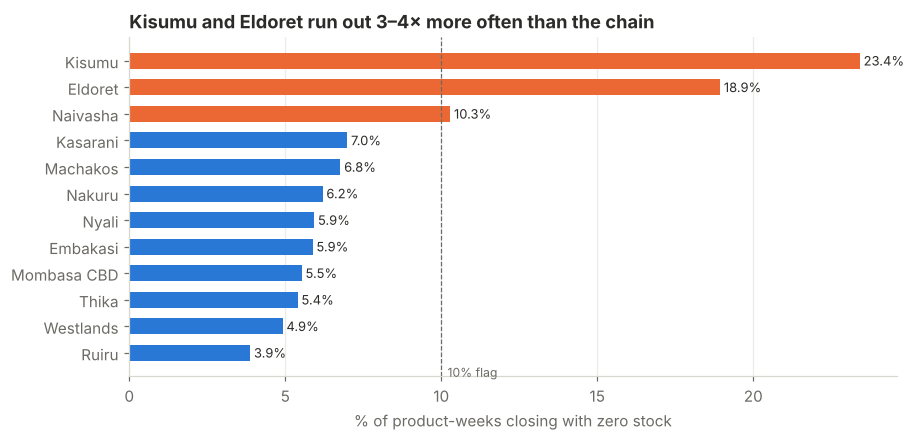

In [3]:
s = an.sql_output("q24_stockout_rate_by_branch").sort_values("stockout_rate_pct")
fig, ax = plt.subplots(figsize=(9, 4))
names = s.branch_name.str.replace("Savanna Fresh ", "")
cols = [an.HIGHLIGHT if v > 10 else an.PRIMARY for v in s.stockout_rate_pct]
ax.barh(names, s.stockout_rate_pct, color=cols, height=.6)
for i, v in enumerate(s.stockout_rate_pct): ax.text(v, i, f" {v:.1f}%", va="center", fontsize=8.5)
ax.axvline(10, color=an.INK_MUTED, ls="--", lw=.8); ax.text(10.2, -.9, "10% flag", fontsize=8, color=an.INK_MUTED)
ax.set_xlabel("% of product-weeks closing with zero stock"); ax.set_title("Kisumu and Eldoret run out 3–4× more often than the chain"); ax.grid(axis="y", visible=False)
an.save(fig, "stockout_rate_by_branch");

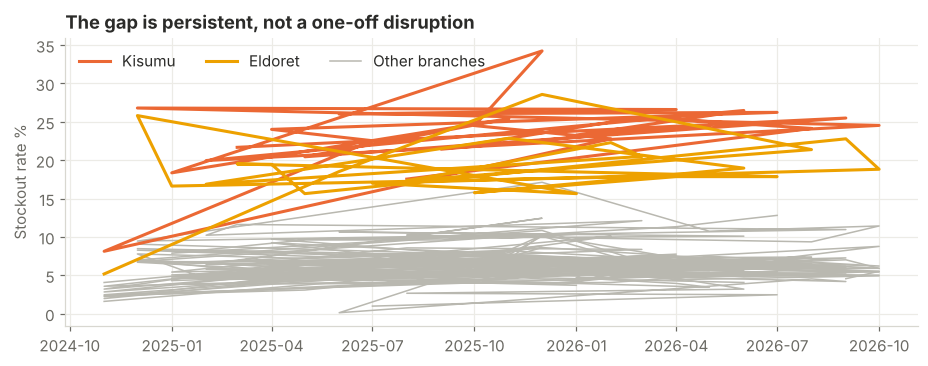

In [4]:
tr = query(engine, "SELECT branch_id, date_trunc('month', snapshot_date)::date AS m, AVG(is_stockout::int)*100 AS rate FROM retail.v_inventory_weekly GROUP BY 1,2")
tr["rate"] = tr.rate.astype(float); tr["m"] = pd.to_datetime(tr.m)
fig, ax = plt.subplots(figsize=(10, 3.4))
for bid, g in tr.groupby("branch_id"):
    hl = {"BR06": (an.HIGHLIGHT, "Kisumu"), "BR11": (an.SERIES[3], "Eldoret")}
    col, lab = hl.get(bid, (an.CONTEXT, None))
    ax.plot(g.m, g.rate, color=col, lw=2 if lab else 1, label=lab, zorder=3 if lab else 1)
ax.plot([], [], color=an.CONTEXT, lw=1, label="Other branches")
ax.set_ylabel("Stockout rate %"); ax.set_title("The gap is persistent, not a one-off disruption"); ax.legend(loc="upper left", ncol=3)
an.save(fig, "stockout_trend");

The elevated rate holds through the whole period, which points to a structural cause (lead time or replenishment parameters) rather than a single supply disruption.

## 3. Root cause: reorder levels (Q22)

In [5]:
r = an.sql_output("q27_reorder_level_adequacy")
piv = r.pivot(index="branch_id", columns="reorder_cover_band", values="avg_stockout_rate_pct")
cnt = r.pivot(index="branch_id", columns="reorder_cover_band", values="branch_product_pairs")
display(piv.round(1)); display(cnt)

reorder_cover_band,0.75-1.25 wk,>= 1.25 wk demand,Reorder level < 0.75 wk demand
branch_id,,,
BR01,6.80,2.20,39.80
BR02,6.40,4.30,40.20
BR03,8.80,5.30,36.30
BR04,8.20,2.80,33.40
BR05,8.00,4.30,38.60
BR06,21.60,19.80,55.10
BR07,7.90,3.50,32.70
BR08,10.80,6.80,41.00
BR09,7.90,4.40,30.00


reorder_cover_band,0.75-1.25 wk,>= 1.25 wk demand,Reorder level < 0.75 wk demand
branch_id,,,
BR01,13,177,12
BR02,18,176,8
BR03,4,188,10
BR04,8,176,18
BR05,11,186,6
BR06,12,171,19
BR07,16,170,16
BR08,14,169,18
BR09,18,179,4


Two separate mechanisms appear:
1. **Stale reorder levels everywhere.** In every branch, the SKUs whose reorder level is below 0.75 weeks of demand stock out in roughly 27–55% of weeks (30–40% in most branches), against 2–7% for SKUs with at least 1.25 weeks of cover. These are a small number of pairs per branch, cheap to fix.
2. **Kisumu and Eldoret stock out even when reorder levels look normal** (17–20% in the ≥1.25-week band versus 2–7% elsewhere). The reorder level is the same multiple of demand as elsewhere, so the shortfall is consistent with **longer delivery lead times** to the two western branches. The reorder point has to cover demand during the lead time, and a one-week buffer cannot cover a two-week delivery cycle. Lead time is not in the dataset, so this is an inference to confirm with the supply chain team.

In [6]:
an.sql_output('q28_lost_sales_estimate')

,branch_id,branch_name,stockout_weeks,est_lost_revenue_kes,est_lost_gross_profit_kes
0,BR06,Savanna Fresh Kisumu,"4,992.00","8,404,477.00","1,568,478.00"
1,BR11,Savanna Fresh Eldoret,"4,036.00","7,102,492.00","1,300,099.00"
2,BR07,Savanna Fresh Nakuru,"1,321.00","4,181,979.00","672,759.00"
3,BR04,Savanna Fresh Nyali,"1,263.00","3,647,730.00","446,832.00"
4,BR01,Savanna Fresh Westlands,"1,049.00","2,120,803.00","435,344.00"
5,BR02,Savanna Fresh Embakasi,"1,253.00","2,534,129.00","419,499.00"
6,BR09,Savanna Fresh Thika,"1,150.00","1,495,313.00","254,789.00"
7,BR05,Savanna Fresh Mombasa CBD,"1,178.00","1,382,904.00","251,089.00"
8,BR08,Savanna Fresh Naivasha,"2,194.00","1,135,190.00","211,569.00"
9,BR03,Savanna Fresh Kasarani,"1,489.00","1,126,862.00","197,758.00"


Estimated gross profit lost to empty shelves (stockout weeks × the pair's normal in-stock weekly profit): Kisumu and Eldoret together account for about KES 2.9M over two years, roughly 48% of the chain-wide estimate of KES 6.0M, although they hold only 15% of sales. The estimate is approximate, because demand during a stockout is unobservable.

## 4. Slow-moving stock and the Household & Cleaning decline (Q15, Q18)

In [7]:
an.sql_output('q22_slow_moving_stock_value')

,stock_status,branch_product_lines,stock_value_kes,share_of_stock_value_pct
0,Healthy,1446,"6,769,103.00",77.60
1,At/below reorder level,822,"1,137,518.00",13.04
2,Slow-moving (>26 wks cover),49,"369,063.00",4.23
3,Overstocked (12-26 wks),84,"319,129.00",3.66
4,No sales in 12 weeks,35,"127,971.00",1.47


In [8]:
an.sql_output('q23_slow_moving_products').head(8)

,product_id,product_name,category,branches_affected,units_on_hand,weekly_units_sold_12w,chain_weeks_of_cover,stock_value_kes
0,P0147,Nyota Clean Toilet Paper 10pk,Household & Cleaning,11,852,2.77,307.70,"277,769.00"
1,P0134,Safi Home Detergent 1kg,Household & Cleaning,9,413,2.69,153.40,"106,034.00"
2,P0178,Savanna Value Biscuits 200g,Snacks & Confectionery,11,608,4.38,138.70,"31,884.00"
3,P0168,Savanna Value Roll-on Deodorant,Personal Care,12,158,0.46,342.30,"30,222.00"
4,P0187,Velvet Cocoa Assorted Sweets 250g,Snacks & Confectionery,10,144,1.23,117.00,"14,089.00"
5,P0167,Lulu Beauty Roll-on Deodorant,Personal Care,12,49,0.15,318.50,"14,000.00"
6,P0106,Pwani Springs Bottled Water 1L,Beverages,1,171,4.38,39.00,"8,037.00"
7,P0097,Kilele Premium Soda 500ml,Beverages,1,57,1.92,29.60,"3,787.00"


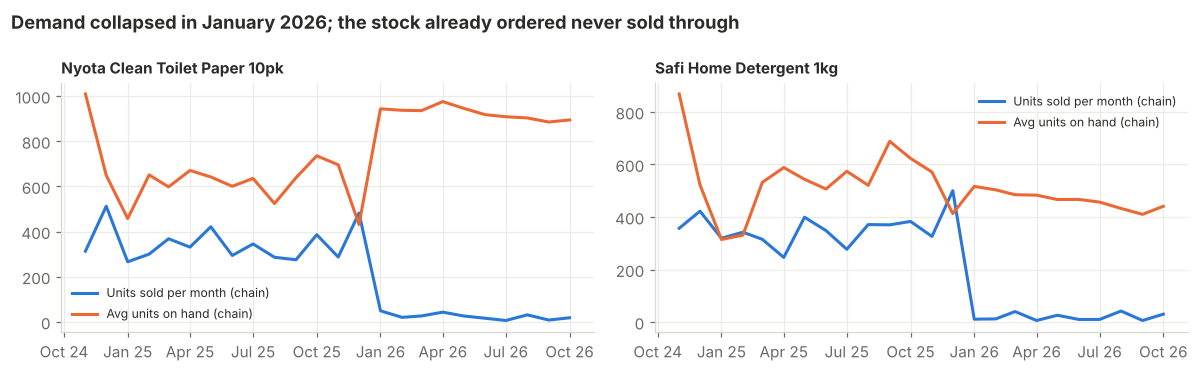

In [9]:
ids = ["P0147", "P0134"]
mm = query(engine, """SELECT product_id, sale_month, SUM(quantity) AS units FROM retail.v_sales_lines
WHERE product_id IN ('P0147','P0134') GROUP BY 1,2 ORDER BY 2""")
st = query(engine, """SELECT product_id, date_trunc('month', snapshot_date)::date AS m, AVG(stock_sum) AS stock FROM
 (SELECT product_id, snapshot_date, SUM(stock_quantity) AS stock_sum FROM retail.inventory_snapshots WHERE product_id IN ('P0147','P0134') GROUP BY 1,2) x GROUP BY 1,2 ORDER BY 1,2""")
names = query(engine, "SELECT product_id, product_name FROM retail.products WHERE product_id IN ('P0147','P0134')").set_index("product_id").product_name
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
for ax, pid in zip(axes, ids):
    a = mm[mm.product_id == pid]; b = st[st.product_id == pid]
    ax.plot(pd.to_datetime(a.sale_month), a.units, color=an.PRIMARY, label="Units sold per month (chain)")
    ax.plot(pd.to_datetime(b.m), b.stock.astype(float), color=an.HIGHLIGHT, label="Avg units on hand (chain)")
    ax.set_title(names[pid], fontsize=10); ax.legend(fontsize=8)
    ax.xaxis.set_major_formatter(__import__("matplotlib.dates", fromlist=["x"]).DateFormatter("%b %y"))
fig.suptitle("Demand collapsed in January 2026; the stock already ordered never sold through", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); an.save(fig, "slow_movers_collapse");

Two Household & Cleaning SKUs (*Nyota Clean Toilet Paper 10pk*, *Safi Home Detergent 1kg*) lost most of their demand from January 2026, but stock on hand did not fall with it. They alone hold about KES 384K of the KES 497K slow-moving or no-sale stock, and their sales drop explains Household & Cleaning's year-on-year decline seen in notebook 05.

Overall, slow and no-sale stock is about 5.7% of stock value (about KES 0.5M at cost), so it is not a balance-sheet problem in itself. The bigger cost is the opportunity: the shelf space and cash could hold faster lines. The data cannot say *why* demand collapsed (a competitor product, price, quality), which is a question for the category buyer.

In [10]:
an.sql_output('q26_replenishment_watchlist').head(15)

,branch_id,product_id,product_name,category,stockout_weeks_12w,latest_stock,reorder_level,weekly_units_when_in_stock,gp_per_selling_week_kes
0,BR01,P0192,Mtoto Soft Diapers 40pk,Baby Care,4,9,3,12.00,"3,097.00"
1,BR07,P0073,Tamu Dairy Cheese 200g,Dairy,5,0,11,38.50,"2,836.00"
2,BR11,P0037,Savanna Farm Tomatoes 1kg,Fresh Produce,3,5,93,67.10,"2,653.00"
3,BR04,P0073,Tamu Dairy Cheese 200g,Dairy,7,0,10,41.20,"2,631.00"
4,BR02,P0073,Tamu Dairy Cheese 200g,Dairy,5,0,9,36.30,"2,629.00"
5,BR06,P0037,Savanna Farm Tomatoes 1kg,Fresh Produce,4,0,77,59.10,"2,351.00"
6,BR07,P0157,Afya Care Body Lotion 400ml,Personal Care,4,8,5,17.80,"2,097.00"
7,BR06,P0192,Mtoto Soft Diapers 40pk,Baby Care,3,0,11,7.90,"2,039.00"
8,BR11,P0073,Tamu Dairy Cheese 200g,Dairy,7,0,8,25.70,"1,868.00"
9,BR06,P0073,Tamu Dairy Cheese 200g,Dairy,4,44,33,24.00,"1,769.00"
